# Baumbestand Berlin

Ergebnisübersicht zur Zusammensetzung, Altersstruktur und räumlichen Verteilung der erfassten Straßen- und Anlagenbäume. Die Tabellen und Abbildungen stammen aus der reproduzierbaren Python-Pipeline. Dieses Notebook liest die enthaltenen Ergebnisse; es startet keinen Netzabruf.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / 'results' / 'summary.json').exists():
    root = root.parent
summary = json.loads((root / 'results' / 'summary.json').read_text(encoding='utf-8'))
composition = pd.read_csv(root / 'results' / 'composition.csv')
districts = pd.read_csv(root / 'results' / 'districts.csv')
ages = pd.read_csv(root / 'results' / 'ages.csv')
summary['snapshot_label']

'WFS-Abruf vom 10.11.2026'

## Datenqualität und Umfang

Fehlende Merkmale bleiben in der Bestandszählung erhalten. Hohe Alterswerte werden dokumentiert und nicht automatisch entfernt.

In [2]:
pd.DataFrame(summary['quality']).T

,records,unknown_genus,unknown_district,missing_or_invalid_age,age_over_200,invalid_or_missing_geometry,points_outside_boundary
Straße,434765.0,9348.0,1589.0,1703.0,67.0,0.0,73.0
Anlage,527780.0,31111.0,4707.0,171954.0,279.0,0.0,NaN


## Zusammensetzung

Die Anteile beziehen sich auf alle Datensätze des jeweiligen Bestandstyps. Unbekannte Gattungsangaben bilden eine eigene Kategorie.

,kind,genus,count,share
0,Anlage,AHORN,130293,0.246870
12,Anlage,EICHE,71558,0.135583
49,Anlage,LINDE,44434,0.084190
88,Anlage,Unbekannt,31111,0.058947
67,Anlage,ROBINIE,27815,0.052702
30,Anlage,HAINBUCHE,26705,0.050599
40,Anlage,KIEFER,25033,0.047431
4,Anlage,BIRKE,21436,0.040615
57,Anlage,PAPPEL,20111,0.038105
8,Anlage,BUCHE,16166,0.030630


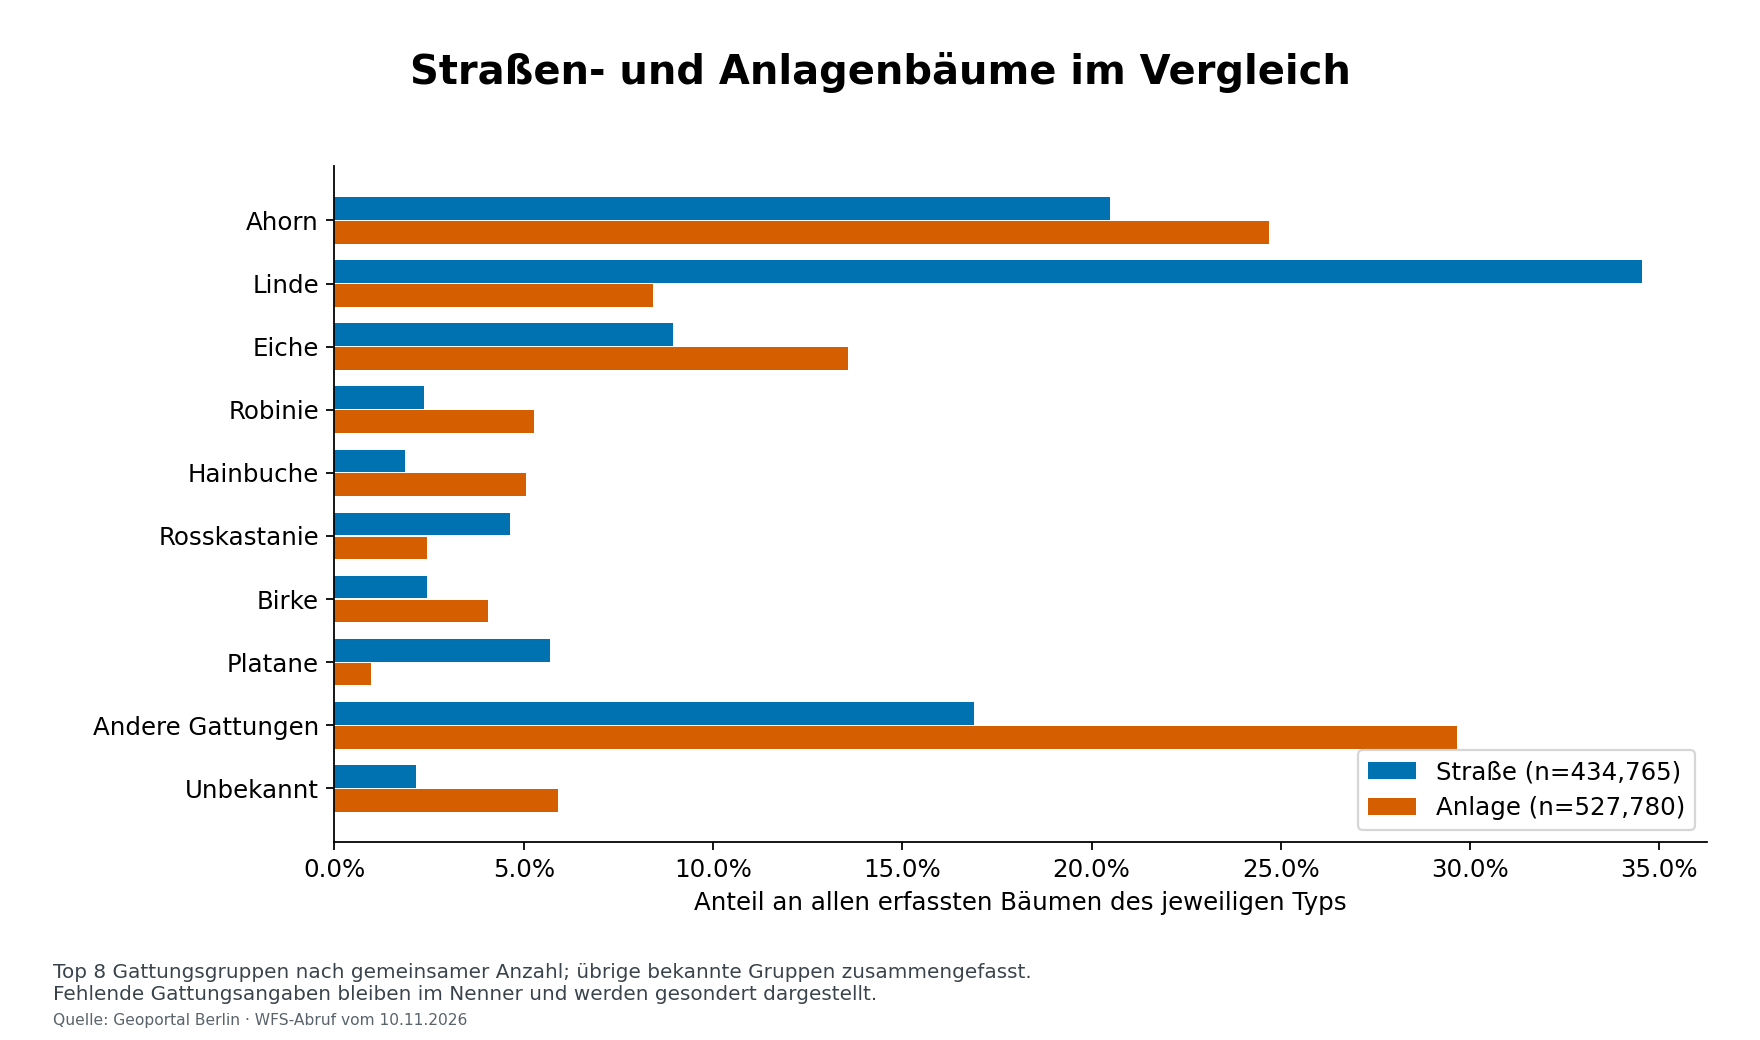

In [3]:
display(composition.sort_values(['kind', 'count'], ascending=[True, False]).groupby('kind').head(10))
display(Image(filename=str(root / 'figures' / 'genus_composition.png'), width=850))

## Räumliche Verteilung

Absolute Straßenbaumzahlen je belegter H3-Zelle. Die Farbskala sättigt am 99%-Quantil; hohe Zählwerte werden nicht aus der Karte entfernt.

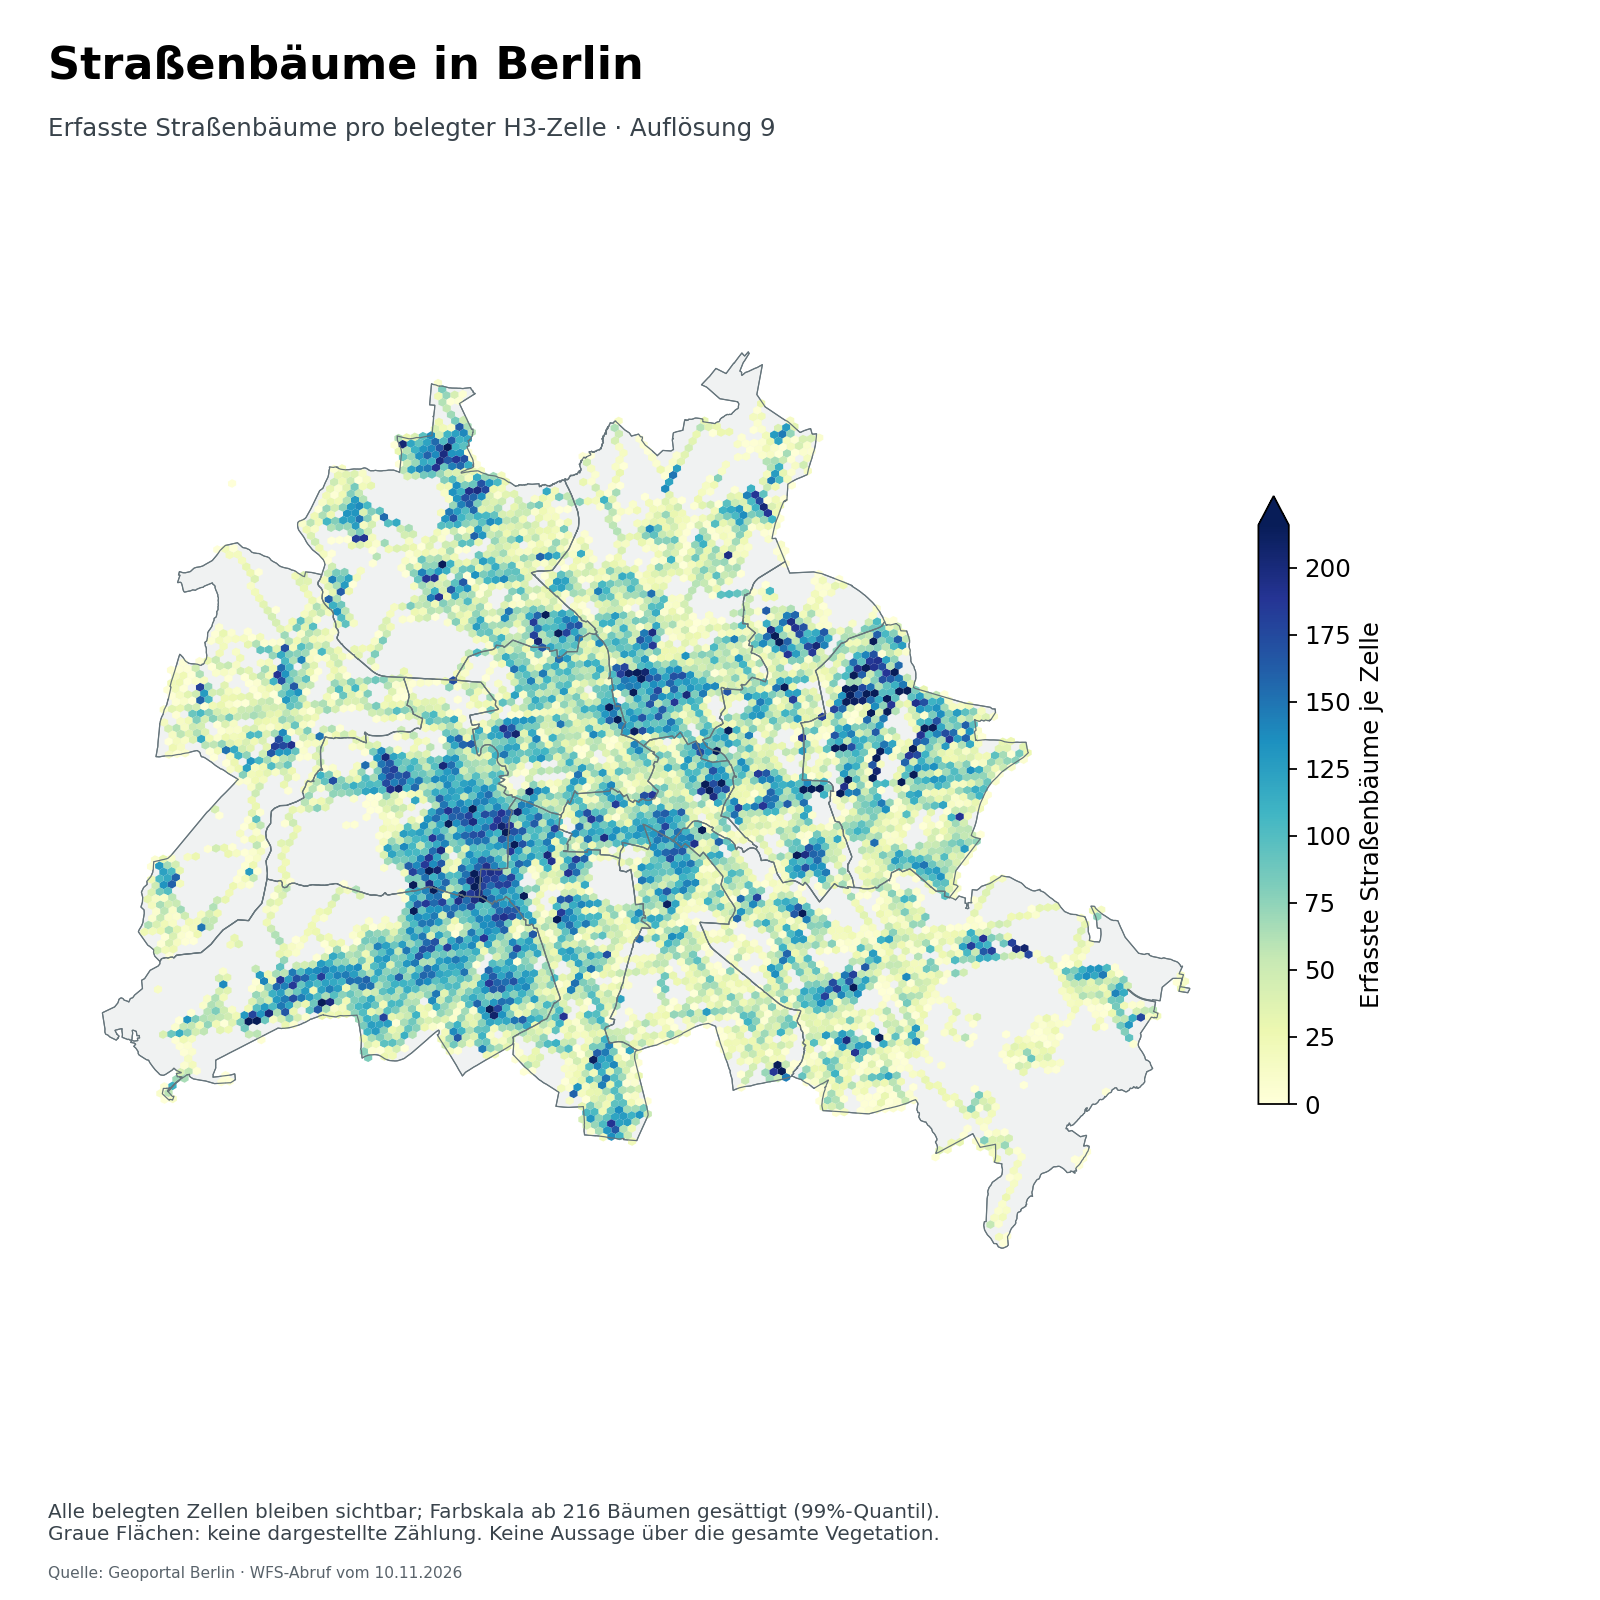

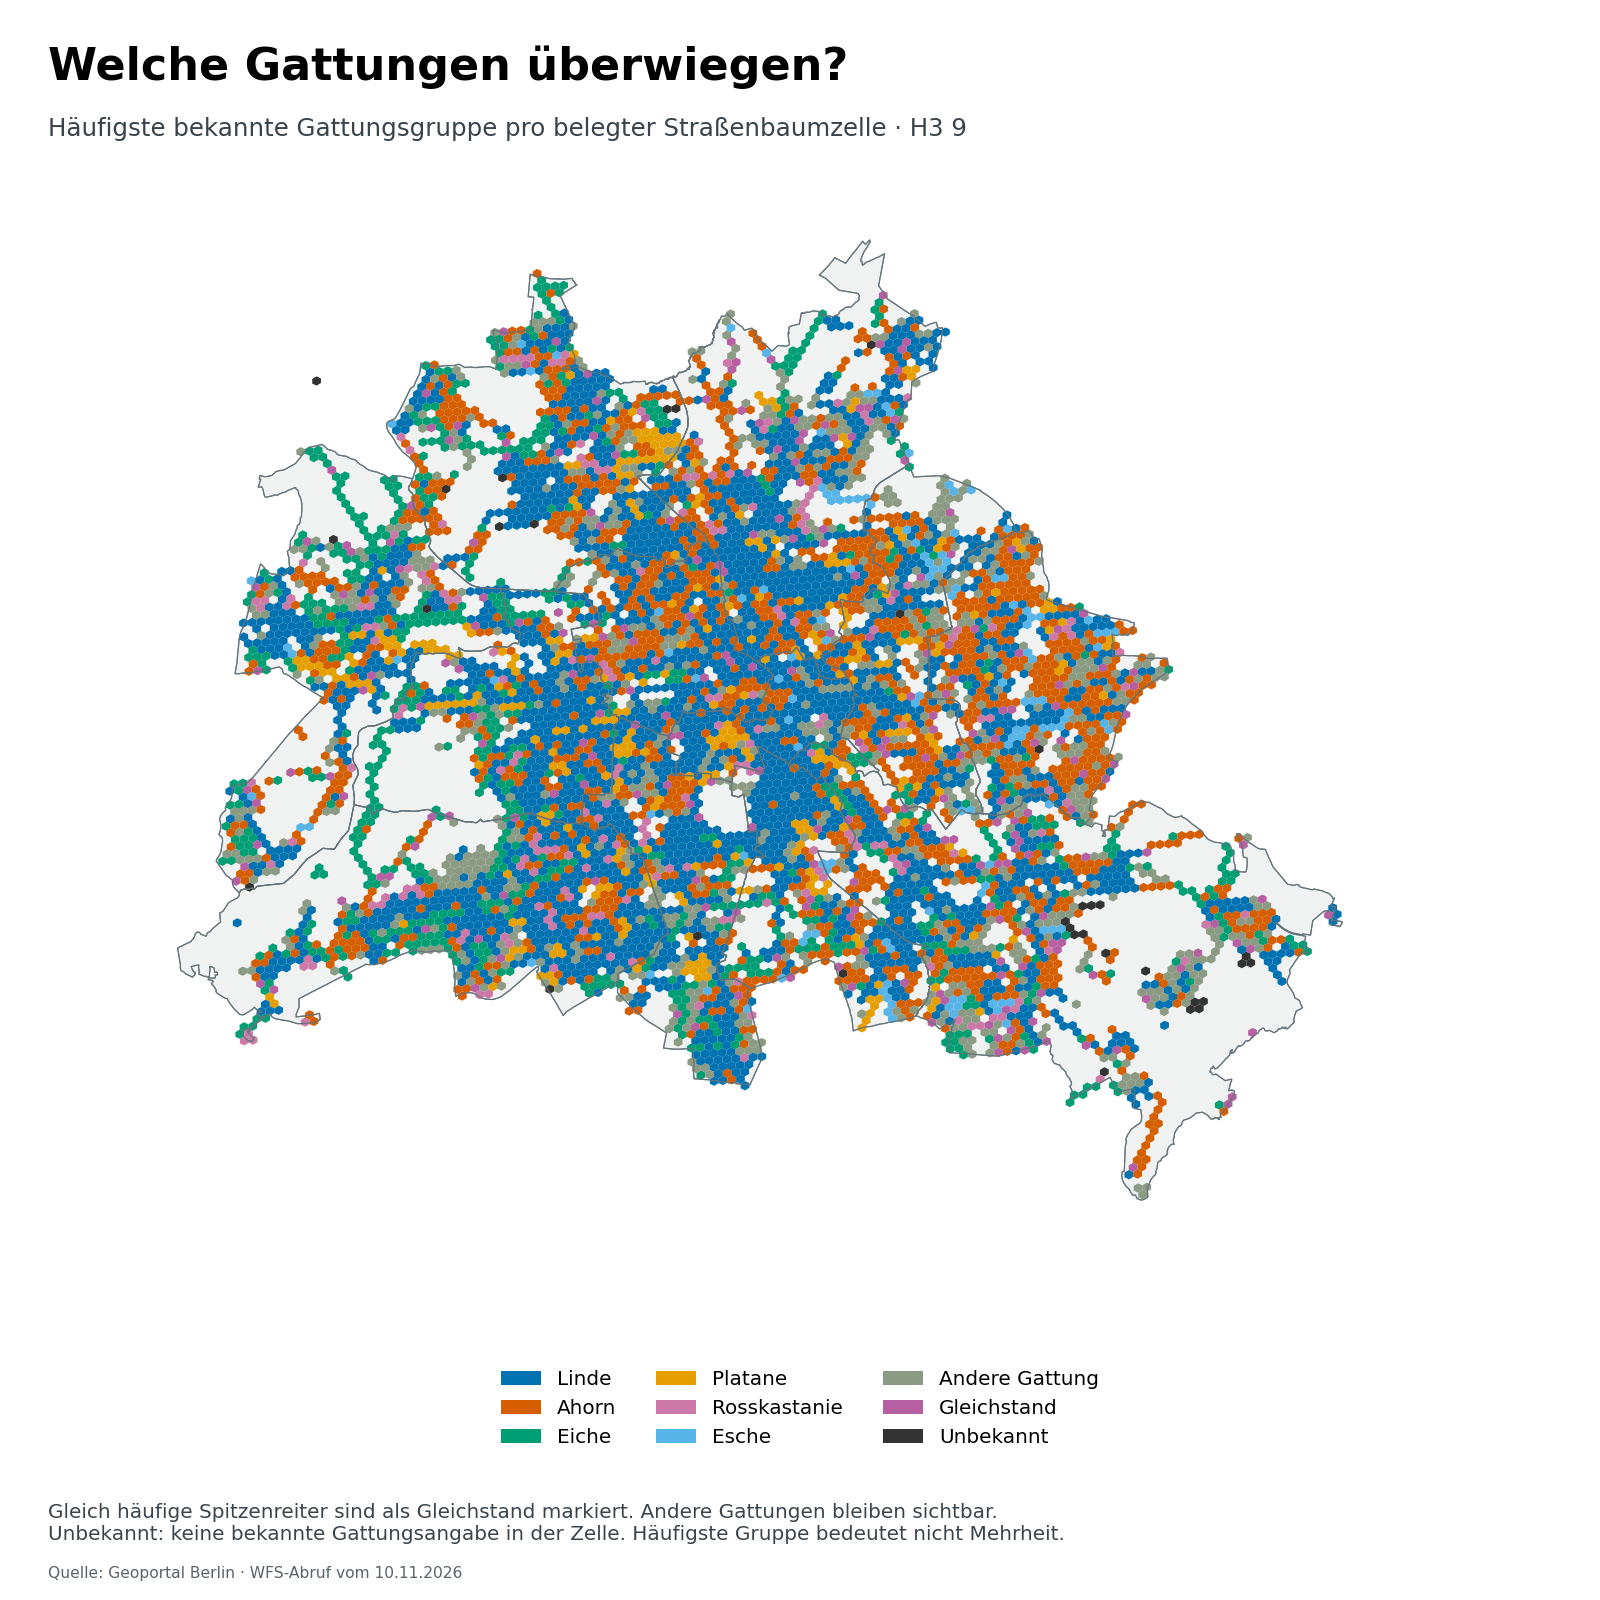

In [4]:
display(Image(filename=str(root / 'figures' / 'street_tree_counts.png'), width=850))
display(Image(filename=str(root / 'figures' / 'dominant_genus.png'), width=850))

## Gattungsdiversität

$H=-\sum_i p_i\ln(p_i)$, $D=\exp(H)$. Berechnung nur aus bekannten Gattungsgruppen. Effektive Gattungszahl und bekannte Anteile werden gemeinsam berichtet. Unterschiedliche Erfassung begrenzt Vergleiche; die Werte messen keine Klimaresilienz.

,kind,district,count,known_genus_share,effective_genera
0,Anlage,Charlottenburg-Wilmersdorf,46932,0.984019,11.944414
1,Anlage,Friedrichshain-Kreuzberg,25190,0.963001,13.646506
2,Anlage,Lichtenberg,50193,0.961528,12.986345
3,Anlage,Marzahn-Hellersdorf,49860,0.933253,13.890389
4,Anlage,Mitte,41550,0.980794,12.038317
5,Anlage,Neukölln,37008,0.959117,14.049134
6,Anlage,Pankow,56124,0.954173,13.831374
7,Anlage,Reinickendorf,48262,0.937073,14.828787
8,Anlage,Spandau,51463,0.859103,13.044548
9,Anlage,Steglitz-Zehlendorf,54293,0.958079,14.251054


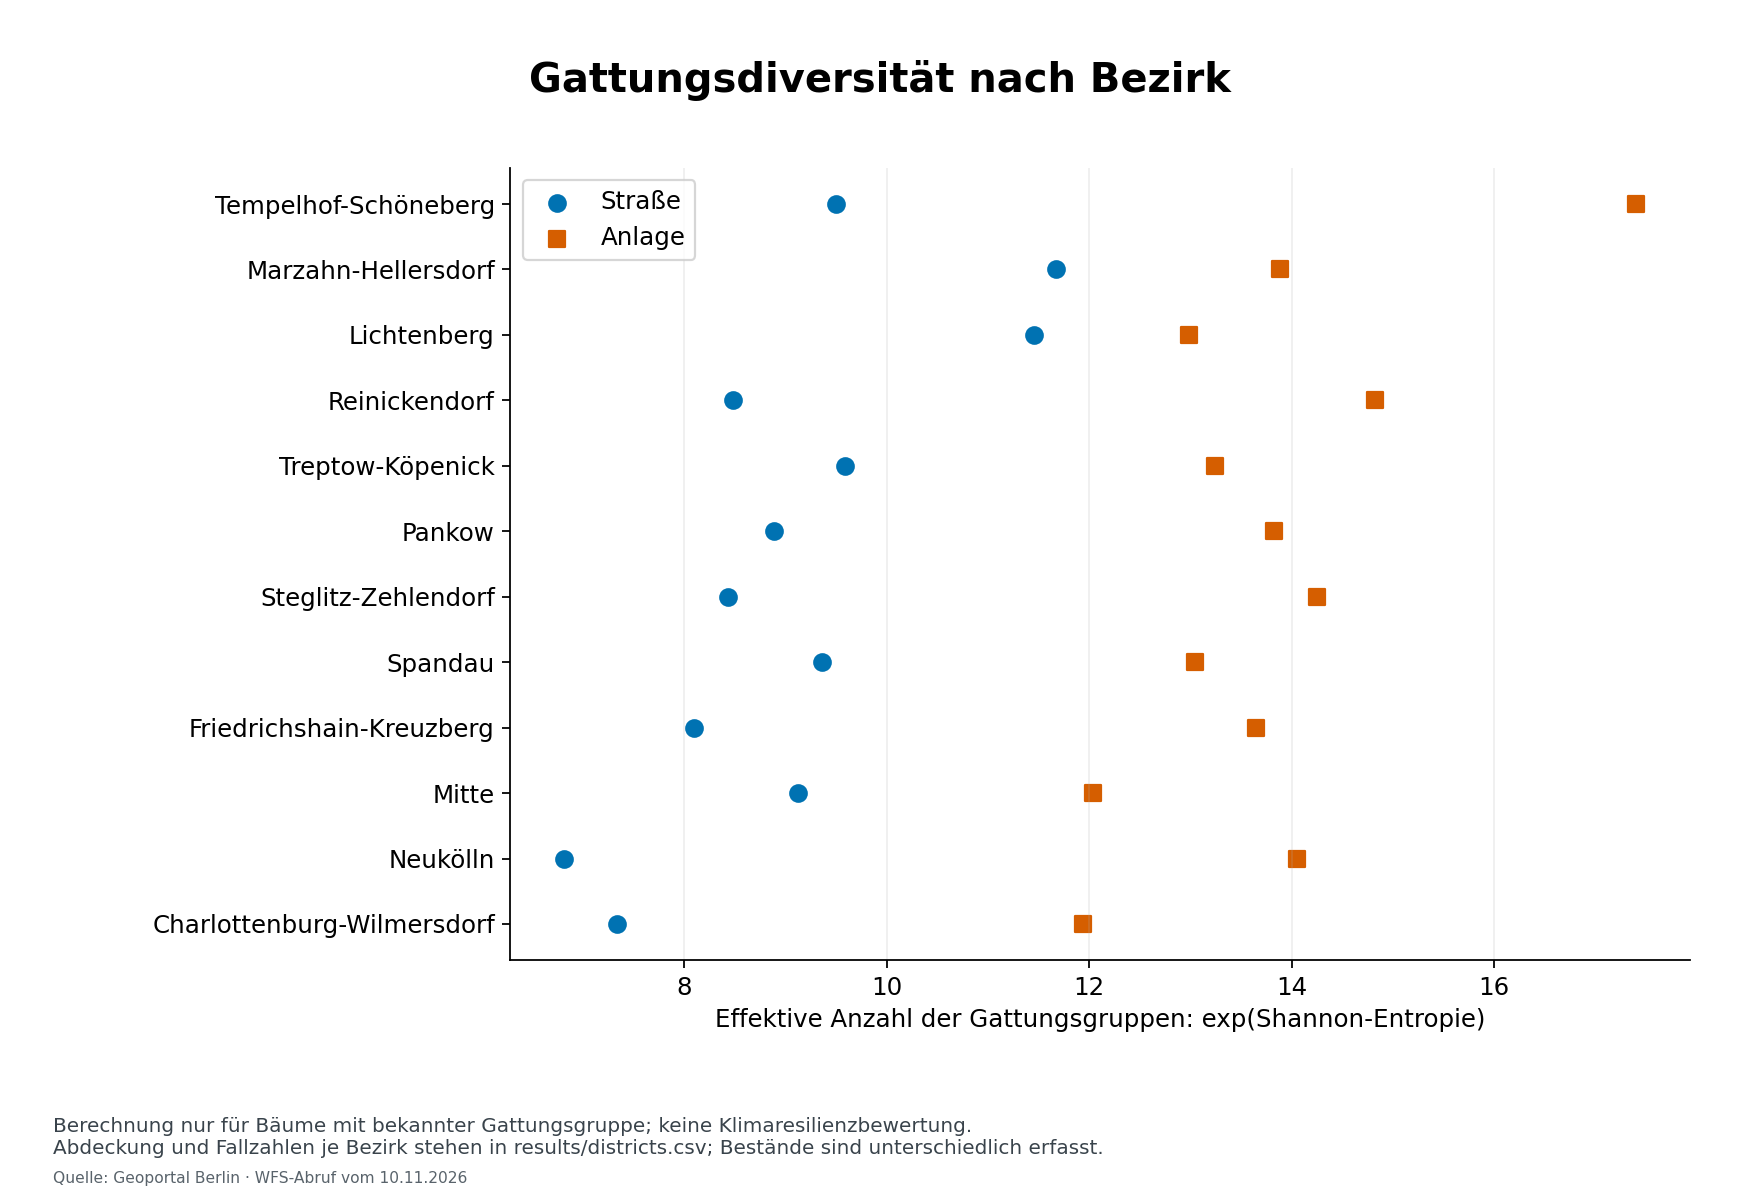

In [5]:
display(districts[['kind', 'district', 'count', 'known_genus_share', 'effective_genera']])
display(Image(filename=str(root / 'figures' / 'district_diversity.png'), width=850))

## Alter

Standalter laut Quelldaten, ohne Fortschreibung auf das heutige Jahr. Unbekannte Alterswerte gehören zum Nenner, und die letzte Klasse ist nach oben offen.

,kind,age_class,count,share
0,Anlage,0–19,56347,0.106762
1,Anlage,100–139,14572,0.027610
2,Anlage,140+,4156,0.007874
3,Anlage,20–39,109161,0.206830
4,Anlage,40–59,93661,0.177462
5,Anlage,60–79,56108,0.106309
6,Anlage,80–99,21821,0.041345
7,Anlage,Unbekannt,171954,0.325806
8,Straße,0–19,60999,0.140303
9,Straße,100–139,13819,0.031785


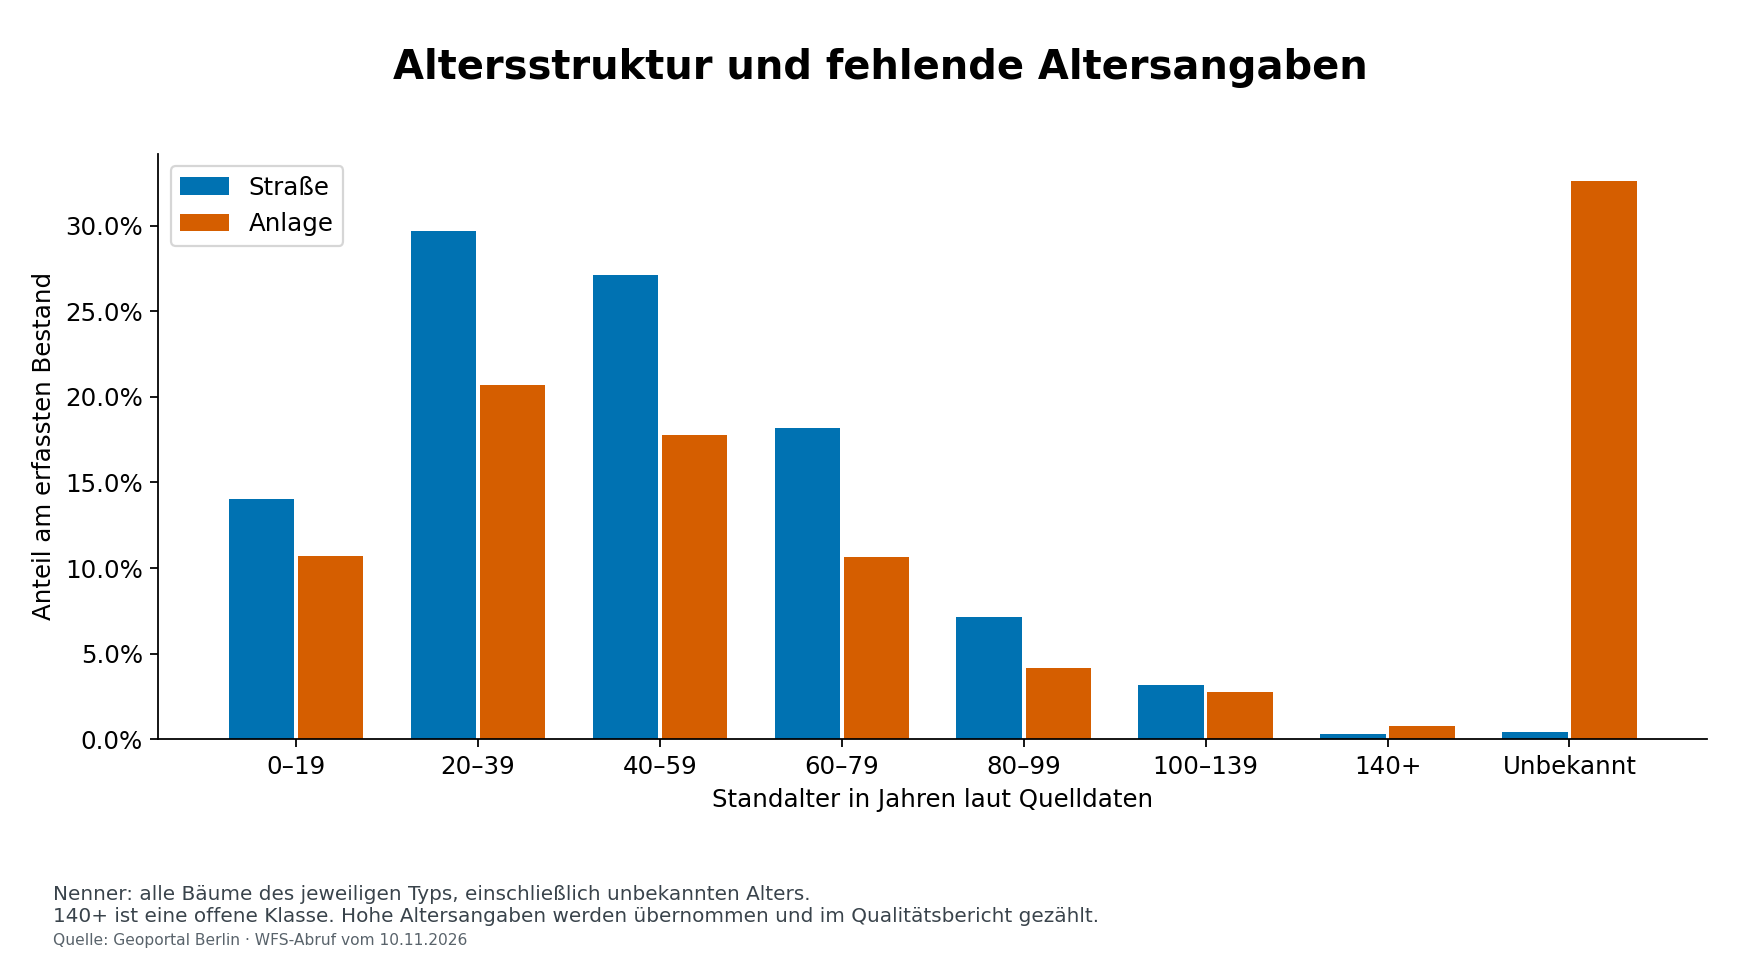

In [6]:
display(ages)
display(Image(filename=str(root / 'figures' / 'age_structure.png'), width=850))

## Einordnung

Das Kataster enthält Straßenbäume und einen Teil der Anlagenbäume. Es bildet weder die gesamte Vegetation noch Baumgesundheit oder Standortqualität ab. Die Analysen sind deskriptiv. Herkunft, Abrufzeit und Prüfsummen sind im Ergebnismanifest dokumentiert; Definitionen und Reproduktion stehen in der README.